# Predicting Heart Disease with Machine Learning (Appendix)
This notebook is an **optional extension** of the data analysis in `01_Heart_Disease_Data_Analysis.ipynb`. It asks one question:

> Given a patient's clinical measurements, can we predict whether they have heart disease?

**Workflow**
1. **Problem definition:** binary classification (heart disease yes/no).
2. **Data:** 302 unique patients and 13 measurements (UCI Cleveland, Kaggle version).
3. **Evaluation:** the proof-of-concept goal is **90% accuracy**.
4. **Features:** see the data dictionary and the analysis notebook.
5. **Modelling:** compare three models, then tune the best ones.
6. **Experimentation:** check the results with cross-validation and decide on next steps.

> **Label note:** the analysis notebook showed that in this file `target = 1` means **no** heart disease. Here we predict `heart_disease = 1 - target`, so that 1 always means *disease*. Accuracy and ROC AUC do not change when the label is flipped. Precision and recall now refer to the disease class.

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

# Splitting, tuning and evaluation
from sklearn.model_selection import train_test_split, cross_val_score, RandomizedSearchCV, GridSearchCV
from sklearn.metrics import confusion_matrix, classification_report, RocCurveDisplay

## 2. Load and prepare the data

In [2]:
df = pd.read_csv("../data/raw/heart-disease.csv").drop_duplicates()   # 302 unique patients

# Features (X) and the corrected outcome (y: 1 = heart disease)
X = df.drop(columns="target")
y = 1 - df["target"]
print(X.shape, "| share with heart disease:", round(y.mean(), 3))

(302, 13) | share with heart disease: 0.457


In [3]:
# Hold back 20% of patients as an unseen test set; the seed makes the split repeatable
np.random.seed(42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)
len(X_train), len(X_test)

(241, 61)

## 3. Baseline models
We try three common classifiers with their default settings:
* **Logistic Regression:** a weighted sum of the features turned into a probability.
* **K-Nearest Neighbours (KNN):** looks at the diagnosis of the most similar patients.
* **Random Forest:** many decision trees vote on the answer.

In [4]:
models = {"Logistic Regression": LogisticRegression(max_iter=1000),
          "KNN": KNeighborsClassifier(),
          "Random Forest": RandomForestClassifier()}

def fit_and_score(models, X_train, X_test, y_train, y_test):
    """Fit each model on the training set and return its accuracy on the test set."""
    np.random.seed(42)
    return {name: model.fit(X_train, y_train).score(X_test, y_test) for name, model in models.items()}

model_scores = fit_and_score(models, X_train, X_test, y_train, y_test)
model_scores

{'Logistic Regression': 0.819672131147541,
 'KNN': 0.6557377049180327,
 'Random Forest': 0.8688524590163934}

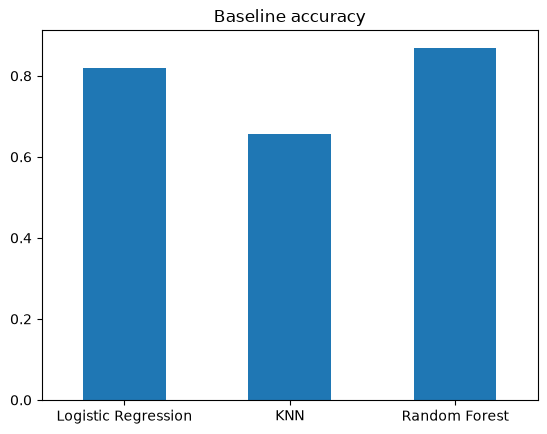

In [5]:
pd.DataFrame(model_scores, index=["accuracy"]).T.plot.bar(legend=False, title="Baseline accuracy", rot=0);

## 4. Hyperparameter tuning
A first score is only a starting point. We tune each model in three ways:
1. **By hand:** KNN, trying 1–20 neighbours.
2. **RandomizedSearchCV:** Logistic Regression and Random Forest, sampling random settings.
3. **GridSearchCV:** Logistic Regression, trying every setting in a grid.

### 4.1 KNN by hand

Best KNN test accuracy: 68.9%


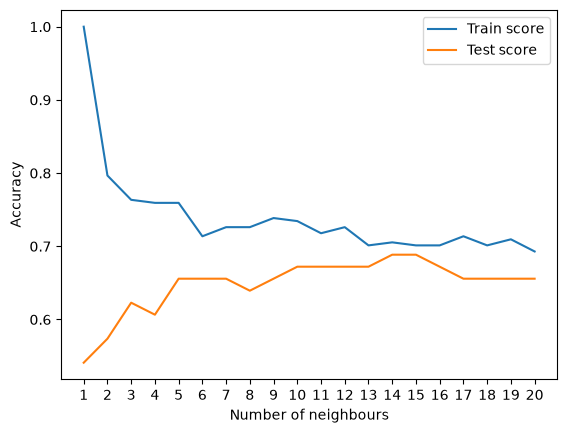

In [6]:
train_scores, test_scores = [], []
neighbors = range(1, 21)
knn = KNeighborsClassifier()

for k in neighbors:
    knn.set_params(n_neighbors=k).fit(X_train, y_train)
    train_scores.append(knn.score(X_train, y_train))
    test_scores.append(knn.score(X_test, y_test))

plt.plot(neighbors, train_scores, label="Train score")
plt.plot(neighbors, test_scores, label="Test score")
plt.xticks(np.arange(1, 21))
plt.xlabel("Number of neighbours")
plt.ylabel("Accuracy")
plt.legend()
print(f"Best KNN test accuracy: {max(test_scores):.1%}")

KNN stays well behind the other two models, so we focus tuning on Logistic Regression and Random Forest.

### 4.2 RandomizedSearchCV

In [7]:
log_reg_grid = {"C": np.logspace(-4, 4, 20), "solver": ["liblinear"]}
rf_grid = {"n_estimators": np.arange(10, 1000, 50), "max_depth": [None, 3, 5, 10],
           "min_samples_split": np.arange(2, 20, 2), "min_samples_leaf": np.arange(1, 20, 2)}

np.random.seed(42)
rs_log_reg = RandomizedSearchCV(LogisticRegression(), log_reg_grid, cv=5, n_iter=20).fit(X_train, y_train)
rs_rf = RandomizedSearchCV(RandomForestClassifier(), rf_grid, cv=5, n_iter=20).fit(X_train, y_train)

print("Logistic Regression:", rs_log_reg.best_params_, f"-> test accuracy {rs_log_reg.score(X_test, y_test):.1%}")
print("Random Forest:      ", rs_rf.best_params_, f"-> test accuracy {rs_rf.score(X_test, y_test):.1%}")

Logistic Regression: {'solver': 'liblinear', 'C': np.float64(0.615848211066026)} -> test accuracy 83.6%
Random Forest:       {'n_estimators': np.int64(760), 'min_samples_split': np.int64(10), 'min_samples_leaf': np.int64(3), 'max_depth': 10} -> test accuracy 88.5%


### 4.3 GridSearchCV on Logistic Regression

In [8]:
gs_log_reg = GridSearchCV(LogisticRegression(), {"C": np.logspace(-4, 4, 30), "solver": ["liblinear"]}, cv=5)
gs_log_reg.fit(X_train, y_train)
print(gs_log_reg.best_params_, f"-> test accuracy {gs_log_reg.score(X_test, y_test):.1%}")

{'C': np.float64(4.893900918477489), 'solver': 'liblinear'} -> test accuracy 82.0%


## 5. Evaluate the tuned model beyond accuracy
On the test set we look at:
* The **ROC curve and AUC**.
* The **confusion matrix**.
* **Precision, recall and F1** in the classification report.

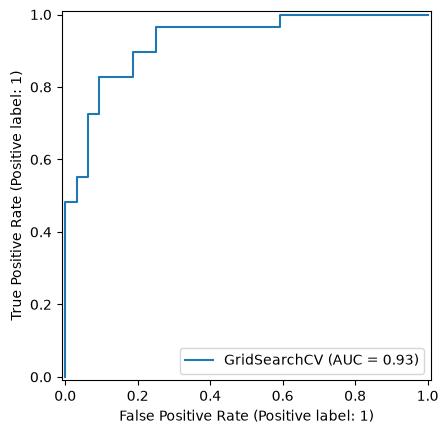

In [9]:
y_preds = gs_log_reg.predict(X_test)
RocCurveDisplay.from_estimator(gs_log_reg, X_test, y_test);

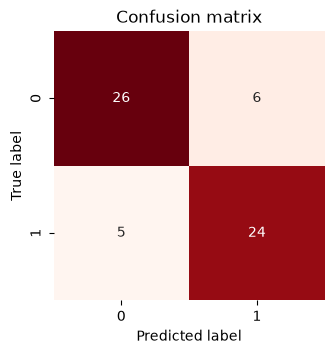

In [10]:
fig, ax = plt.subplots(figsize=(3.5, 3.5))
sns.heatmap(confusion_matrix(y_test, y_preds), annot=True, cbar=False, cmap="Reds", ax=ax)
ax.set(xlabel="Predicted label", ylabel="True label", title="Confusion matrix");

In [11]:
print(classification_report(y_test, y_preds, target_names=['No disease', 'Heart disease']))

               precision    recall  f1-score   support

   No disease       0.84      0.81      0.83        32
Heart disease       0.80      0.83      0.81        29

     accuracy                           0.82        61
    macro avg       0.82      0.82      0.82        61
 weighted avg       0.82      0.82      0.82        61



### 5.1 Cross-validated metrics
A single test split can be lucky or unlucky. With **5-fold cross-validation**, every patient is used for testing exactly once.

accuracy     0.831
precision    0.850
recall       0.769
f1           0.804
dtype: float64

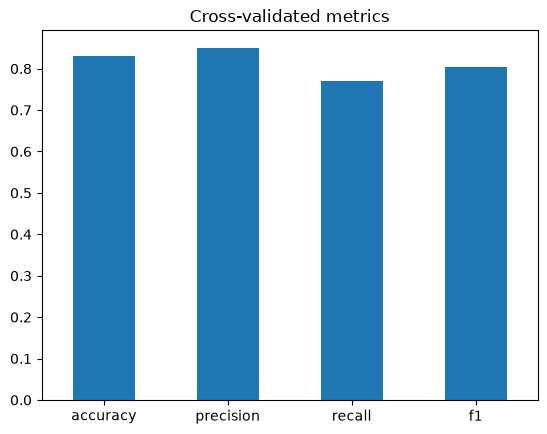

In [12]:
clf = LogisticRegression(**gs_log_reg.best_params_)
cv_metrics = {m: cross_val_score(clf, X, y, cv=5, scoring=m).mean()
              for m in ["accuracy", "precision", "recall", "f1"]}
cv_metrics = pd.Series(cv_metrics).round(3)
cv_metrics.plot.bar(title="Cross-validated metrics", rot=0)
cv_metrics

## 6. Feature importance
Logistic Regression gives each feature a weight (coefficient):
* A **positive** weight pushes the prediction towards heart disease.
* A **negative** weight pushes it towards no disease.

The features are on different scales, so compare the signs. Don't over-read the sizes.

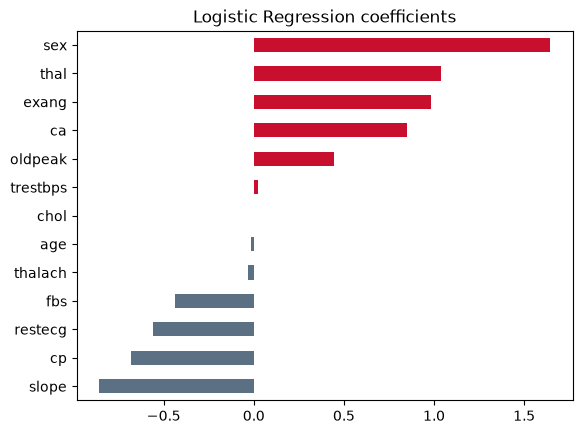

In [13]:
clf.fit(X_train, y_train)
importance = pd.Series(clf.coef_[0], index=X.columns).sort_values()
importance.plot.barh(title="Logistic Regression coefficients", color=np.where(importance > 0, "#C8102E", "#5B7083"));

## 7. Conclusion and next steps
* On the single test split, the **tuned Random Forest scores highest (about 88.5%)**. Tuned Logistic Regression scores about 82%.
* Logistic Regression is evaluated in detail because its weights are easy to explain. Its **cross-validated accuracy is about 83%**.
* **No model reliably reaches the 90% goal**, and scores move by several points depending on which patients land in the test set.
* The strongest model features match the analysis notebook: chest-pain type, vessels narrowed, thallium result, exercise angina and ST depression.

**To get closer to 90%:**
* Collect more patients (combine the other UCI sites).
* Scale the features and one-hot encode the categories in a scikit-learn `Pipeline`.
* Try gradient-boosting models such as XGBoost or CatBoost.